In [1]:
from auxin_signalling_models.ReducedAuxinSignallingPathway import \
    ReducedAuxinSignallingPathway as reduced_asp_class
from auxin_signalling_models.AuxinSignallingPathway import AuxinSignallingPathway as asp_class

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import sympy as sp
import scipy

In [2]:
kwargs = {'nARFs': 1, 'nIAAs': 1}

asp_model_r = reduced_asp_class(**kwargs, include_arf_transcription=True)
asp_model_full = asp_class(**kwargs, include_arf_transcription=True)

In [3]:
# Find all parameters related to the promoter-protein dynamics
empty_set_node = asp_model_full.empty_set_node
aux_symbol = asp_model_full.auxin_variable_label

pp_reactions = []
promoter_symbols = [s.name for s in asp_model_full.get_state_variables() if s.category=="promoter"]

asp_model_full.remove_state_variable_by_name("G__ARF_1")

for r in asp_model_full._reactions_set:
    if np.all(np.isin(r.reactants + r.products, promoter_symbols)):
        pp_reactions.append(r)
    
pp_parameters = [s for r in pp_reactions for s in r.fwd_rates + r.bwd_rates]
print(asp_model_full.get_default_parameters())
print(pp_parameters)

{'d__D__ARF_1__ARF_1': 0.1, 'd__D__ARF_1__iaa_1': 0.1, 'd__D__iaa_1__iaa_1': 0.1, 'd__G__ARF_1': 1.0, 'd__G__ARF_1__ARF_1': 1.0, 'd__G__ARF_1__iaa_1': 1.0, 'd__R': 0.01, 'd__arf__all': 1.0, 'd__iaa_1__x': 0.1, 'd__iaa__all': 1.0, 'k__D__ARF_1__ARF_1': 0.001, 'k__D__ARF_1__iaa_1': 0.001, 'k__D__iaa_1__iaa_1': 0.001, 'k__G__ARF_1': 1.0, 'k__G__ARF_1__ARF_1': 1.0, 'k__G__ARF_1__ARF_1__R__ARF_1': 1.0, 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__R__ARF_1': 1.0, 'k__G__ARF_1__R__iaa_1': 1.0, 'k__G__ARF_1__iaa_1': 1.0, 'k__G__ARF_1__iaa_1__R__ARF_1': 1.0, 'k__G__ARF_1__iaa_1__R__iaa_1': 1.0, 'k__G__R__ARF_1': 1.0, 'k__G__R__iaa_1': 1.0, 'k__R__ARF_1__ARF_1': 1.0, 'k__R__iaa_1__iaa_1': 1.0}
['d__G__ARF_1__ARF_1', 'k__G__ARF_1__ARF_1', 'd__G__ARF_1__iaa_1', 'k__G__ARF_1__iaa_1']


In [4]:
promoter_timeconstant = 'tau_G'
asp_model_full.add_model_parameter(promoter_timeconstant, 1.0, "Promoter timeconstant", strict=False)
asp_model_full.add_model_parameter("k__RNA__IAA", 1.0, "", strict=False)

full_parameter_subs_dict = asp_model_r.parameter_subs_dict.copy()

for p in pp_parameters:
    if p in full_parameter_subs_dict:
        print(f"{full_parameter_subs_dict[p]}")
    else:
        full_parameter_subs_dict[p] = sp.sympify(p) / sp.sympify(promoter_timeconstant)

print(full_parameter_subs_dict)

tau_G
k__RNA__IAA
{'k__R__iaa_1__iaa_1': 'k__RNA__IAA', 'k__R__ARF_1__ARF_1': 'k__RNA__ARF', 'd__G__ARF_1__ARF_1': d__G__ARF_1__ARF_1/tau_G, 'k__G__ARF_1__ARF_1': k__G__ARF_1__ARF_1/tau_G, 'd__G__ARF_1__iaa_1': d__G__ARF_1__iaa_1/tau_G, 'k__G__ARF_1__iaa_1': k__G__ARF_1__iaa_1/tau_G}


In [5]:
# Generate initial conditions
reduced_ic_dict = asp_model_r.get_default_initial_conditions()
full_ic_dict = asp_model_full.get_default_initial_conditions()

jac_func, inhomog_func = asp_model_r.get_promoter_ode_funcs()

# Randomise parameters slightly
reduced_param_dict = asp_model_r.get_default_parameters()
for k in reduced_param_dict:
    reduced_param_dict[k] *= 10**np.random.uniform(0, .1)

reduced_ic_dict = asp_model_r.get_default_initial_conditions()

full_param_dict = reduced_param_dict.copy()

odes, free_variables, parameters, constraints = \
    asp_model_r.generate_ode_system(reduced=True)

params = np.array(list(asp_model_r.get_default_parameters().values()))

jac = jac_func(np.array(list(reduced_ic_dict.values())).astype(np.float64), 
               params,
               np.array([1.0]))

inhomog = inhomog_func(np.array(list(reduced_ic_dict.values())), 
                        params, [1.0])

promoter_symbols = [s.name for s in asp_model_full.get_state_variables() if s.category=="promoter"]

initial_promoter_vars = np.linalg.solve(jac, -inhomog).flatten()
initial_promoter_vars = np.concatenate([[1.0 - initial_promoter_vars.sum()], initial_promoter_vars])


print(promoter_symbols)
print(initial_promoter_vars)
# We can set the initial conditions to be identical, but this produces less interesting plots:
for i, p in enumerate(promoter_symbols):
    # break
    full_ic_dict[p] = initial_promoter_vars[i]
    

['G', 'G__ARF_1__ARF_1', 'G__ARF_1__iaa_1']
[0.83333333 0.08333333 0.08333333]


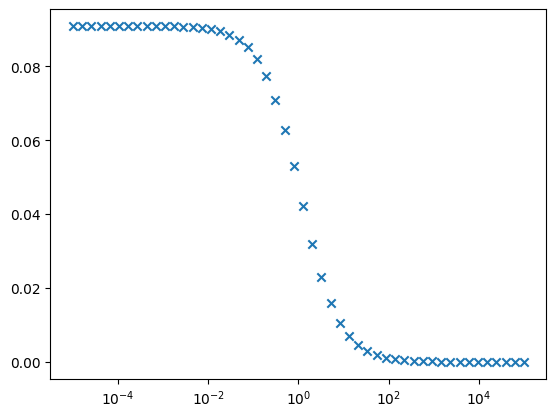

In [6]:
vals = 10**np.linspace(-5, 5, 50)
_params = params.copy()

ics = np.array(list(reduced_ic_dict.values()))
var_index = sorted(list(reduced_ic_dict.keys())).index('D__ARF_1__ARF_1')
plot_points = []
for val in vals:
    ics[var_index] = val
    jac = jac_func(ics, 
               _params,
               np.array([1.0]))
    
    cond_number = np.linalg.det(jac@jac.T)
    inhomog = inhomog_func(ics, 
                        _params, [1.0])
    initial_promoter_vars = -np.linalg.solve(jac, inhomog).flatten()
    assert np.all(initial_promoter_vars > 0)
    plot_points.append((val, initial_promoter_vars[-1]))


plt.scatter(*np.vstack(plot_points).T, marker='x')
plt.xscale('log')

{'k__R__iaa_1__iaa_1': 'k__RNA__IAA', 'k__R__ARF_1__ARF_1': 'k__RNA__ARF', 'd__G__ARF_1__ARF_1': d__G__ARF_1__ARF_1/tau_G, 'k__G__ARF_1__ARF_1': k__G__ARF_1__ARF_1/tau_G, 'd__G__ARF_1__iaa_1': d__G__ARF_1__iaa_1/tau_G, 'k__G__ARF_1__iaa_1': k__G__ARF_1__iaa_1/tau_G}
Matrix([[-2*ARF_1**2*k__D__ARF_1__ARF_1 - ARF_1*d__arf__all - ARF_1*iaa_1*k__D__ARF_1__iaa_1 + 2*D__ARF_1__ARF_1*d__D__ARF_1__ARF_1 + D__ARF_1__iaa_1*d__D__ARF_1__iaa_1 + R__ARF_1*k__RNA__ARF], [ARF_1**2*k__D__ARF_1__ARF_1 - D__ARF_1__ARF_1*d__D__ARF_1__ARF_1], [ARF_1*iaa_1*k__D__ARF_1__iaa_1 - D__ARF_1__iaa_1*d__D__ARF_1__iaa_1], [-D__iaa_1__iaa_1*d__D__iaa_1__iaa_1 + iaa_1**2*k__D__iaa_1__iaa_1], [(-D__ARF_1__ARF_1*G*k__G__ARF_1__ARF_1 - D__ARF_1__iaa_1*G*k__G__ARF_1__iaa_1 + G__ARF_1__ARF_1*d__G__ARF_1__ARF_1 + G__ARF_1__iaa_1*d__G__ARF_1__iaa_1)/tau_G], [(D__ARF_1__ARF_1*G*k__G__ARF_1__ARF_1 - G__ARF_1__ARF_1*d__G__ARF_1__ARF_1)/tau_G], [(D__ARF_1__iaa_1*G*k__G__ARF_1__iaa_1 - G__ARF_1__iaa_1*d__G__ARF_1__iaa_1)/tau_G],

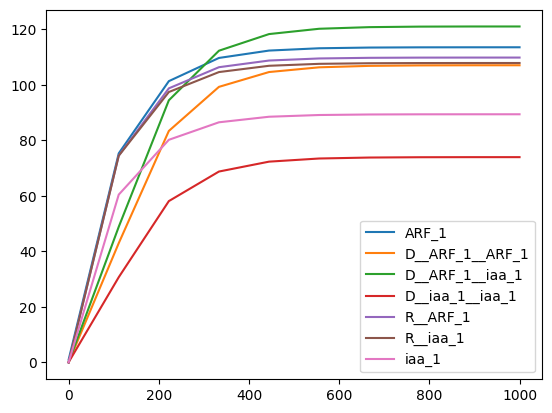

In [7]:
reduced_solver = asp_model_r.make_forward_solver()

print(full_parameter_subs_dict)

ts = np.linspace(0, 1e3, 10)

sol1, succ = reduced_solver(ts, reduced_param_dict, reduced_ic_dict, 1)
r_odes, free_variables, parameters, constraints = asp_model_r.generate_ode_system()
f_odes, free_variables, parameters, constraints = asp_model_full.generate_ode_system(parameter_subs_dict=full_parameter_subs_dict)

plt.plot(ts, sol1, label=reduced_ic_dict.keys())
plt.legend()

print(sp.simplify(f_odes))

['d__D__ARF_1__ARF_1', 'd__D__ARF_1__iaa_1', 'd__D__iaa_1__iaa_1', 'd__G__ARF_1', 'd__G__ARF_1__ARF_1', 'd__G__ARF_1__iaa_1', 'd__R', 'd__arf__all', 'd__iaa_1__x', 'd__iaa__all', 'k__D__ARF_1__ARF_1', 'k__D__ARF_1__iaa_1', 'k__D__iaa_1__iaa_1', 'k__G__ARF_1', 'k__G__ARF_1__ARF_1', 'k__G__ARF_1__ARF_1__R__ARF_1', 'k__G__ARF_1__ARF_1__R__iaa_1', 'k__G__ARF_1__R__ARF_1', 'k__G__ARF_1__R__iaa_1', 'k__G__ARF_1__iaa_1', 'k__G__ARF_1__iaa_1__R__ARF_1', 'k__G__ARF_1__iaa_1__R__iaa_1', 'k__G__R__ARF_1', 'k__G__R__iaa_1', 'k__RNA__ARF', 'k__RNA__IAA', 'tau_G']
{'d__D__ARF_1__ARF_1': 0.1, 'd__D__ARF_1__iaa_1': 0.1, 'd__D__iaa_1__iaa_1': 0.1, 'd__G__ARF_1': 1.0, 'd__G__ARF_1__ARF_1': 1.0, 'd__G__ARF_1__iaa_1': 1.0, 'd__R': 0.01, 'd__arf__all': 1.0, 'd__iaa_1__x': 0.1, 'd__iaa__all': 1.0, 'k__D__ARF_1__ARF_1': 0.001, 'k__D__ARF_1__iaa_1': 0.001, 'k__D__iaa_1__iaa_1': 0.001, 'k__G__ARF_1': 1.0, 'k__G__ARF_1__ARF_1': 1.0, 'k__G__ARF_1__ARF_1__R__ARF_1': 1.0, 'k__G__ARF_1__ARF_1__R__iaa_1': 1.0, 'k__G

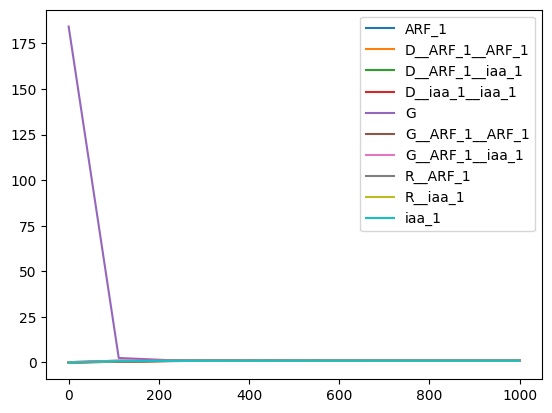

In [8]:

full_param_dict = asp_model_full.get_default_parameters(parameter_subs_dict=asp_model_r.parameter_subs_dict)

for k, v in reduced_param_dict.items():
    full_param_dict[k] = v

full_param_dict[promoter_timeconstant] = 1e-10

print(list(full_param_dict.keys()))
print(asp_model_full.get_default_parameters())

full_solver = asp_model_full.make_forward_solver(parameter_subs_dict=full_parameter_subs_dict)
sol2, succ = full_solver(ts, full_param_dict, full_ic_dict, 1, strict=False)

print(full_ic_dict.keys())
plt.plot(ts, sol2 / sol2[-1, :], label=full_ic_dict.keys())
plt.legend()

odes, free_variables, parameters, \
            _ = asp_model_r.generate_ode_system(
                                         reduced=True)

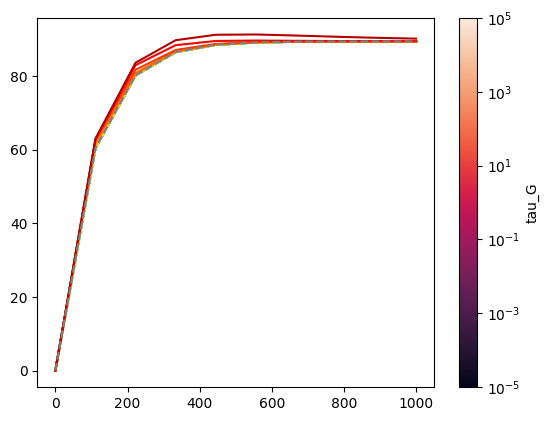

In [12]:
plt.clf()

cmap = plt.get_cmap('jet') 

rmses = []
tau_vals = 10**np.linspace(-5, 5, 20)

parameter_subs_dict = asp_model_r.parameter_subs_dict
full_param_dict = asp_model_full.get_default_parameters(parameter_subs_dict=parameter_subs_dict)

for k, v in reduced_param_dict.items():
    full_param_dict[k] = v

parameter_subs_dict = asp_model_r.parameter_subs_dict
for i, tau in enumerate(tau_vals):
    # full_param_dict = asp_model_full.get_default_parameters(parameter_subs_dict=parameter_subs_dict)
    full_param_dict[promoter_timeconstant] = tau
    sol2, succ = full_solver(ts, full_param_dict, full_ic_dict, 1)
    color = cmap(i / len(tau_vals)) 
    plt.plot(ts, sol2[:, -1], color=color)
    
    rmse = np.sqrt(np.mean((sol2[1:, -1] - sol1[1:, -1])**2))
    rmses.append(rmse)

plt.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.LogNorm(tau_vals[0], tau_vals[-1]), cmap='rocket'),
             orientation='vertical', label='tau_G', ax=plt.gca())
plt.plot(ts, sol1[:, -1], color='grey', ls='--')


In [13]:
steps_taken_list = []
x0 = np.array(list(full_ic_dict.values()))
p = np.array(list(full_param_dict.values()))

_ts = [ts[0], ts[-1]]
parameter_subs_dict = full_parameter_subs_dict

_rhs_func = asp_model_full.generate_rhs_func(parameter_subs_dict=parameter_subs_dict)

def wrapped_rhs_func(t, y, p, aux):
    return _rhs_func(y, t, p, aux).flatten()

jac_func = asp_model_full.generate_jacobian_func(parameter_subs_dict=parameter_subs_dict)
def wrapped_jac_func(t, y, p, aux):
    return jac_func(y, t, p, aux)

for i, tau in enumerate(tau_vals):
    print(tau)
    full_param_dict[promoter_timeconstant] = tau
    p = np.array(list([full_param_dict[k] for k in sorted(full_param_dict.keys())]))
    res = scipy.integrate.solve_ivp(wrapped_rhs_func, t_span=_ts, y0=x0, args=[p, [1.0]],
                                    full_output=True, method="LSODA", jac=wrapped_jac_func)
    steps_taken = res.nfev
    steps_taken_list.append(steps_taken)
print(steps_taken_list)



1e-05
3.359818286283781e-05
0.00011288378916846884
0.000379269019073225
0.0012742749857031334
0.004281332398719391
0.01438449888287663
0.04832930238571752
0.1623776739188721
0.5455594781168515
1.8329807108324339
6.1584821106602545
20.6913808111479
69.51927961775606
233.57214690901213
784.7599703514607
2636.6508987303555
8858.667904100832
29763.51441631313
100000.0
[278, 248, 252, 250, 249, 250, 280, 282, 265, 229, 227, 260, 255, 217, 183, 185, 167, 171, 165, 143]


/home/pmzjs/code/auxin_signalling_models/.venv/lib/python3.12/site-packages/scipy/integrate/_ivp/ivp.py:623: UserWarning: The following arguments have no effect for a chosen solver: `full_output`.
  solver = method(fun, t0, y0, tf, vectorized=vectorized, **options)


[[-1.27379612 -0.11060917]
 [-0.11986857 -1.34471094]]
[-1.10775276 -0.01115444 -0.01033935 -0.01108144  1.02720749  1.18062345
 -0.09107172]


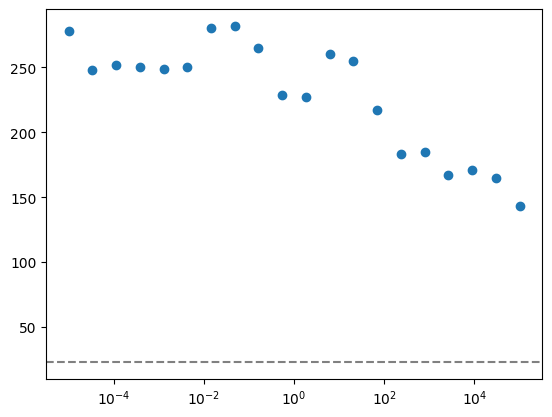

In [14]:
# Now the reduced model
x0 = np.array(list(reduced_ic_dict.values()))
p = np.array(list(reduced_param_dict.values()))

_rhs_func = asp_model_r.generate_rhs_func()

def wrapped_rhs_func(t, y, p, aux):
    return _rhs_func(y, t, p, aux).flatten()


promoter_expr_jac_func, inhomog_expr_func\
        = asp_model_r.get_promoter_ode_funcs()

print(promoter_expr_jac_func(x0, p, [1.0]))

print(wrapped_rhs_func(0, x0, p, [1.0]))


jac_func = asp_model_full.generate_jacobian_func(parameter_subs_dict=parameter_subs_dict)
def wrapped_jac_func(t, y, p, aux):
    return jac_func(y, t, p, aux)

res = scipy.integrate.solve_ivp(wrapped_rhs_func, t_span = [0, 1], y0=x0, args=(p, [1.0]),
                                    full_output=True, method="LSODA")
y = res.y

steps_taken = res.nfev

plt.scatter(tau_vals, steps_taken_list)

ax = plt.gca()
ax.axhline(steps_taken, ls='--', color='grey')
ax.set_xscale('log')

Text(0.5, 0, 'tau_G')

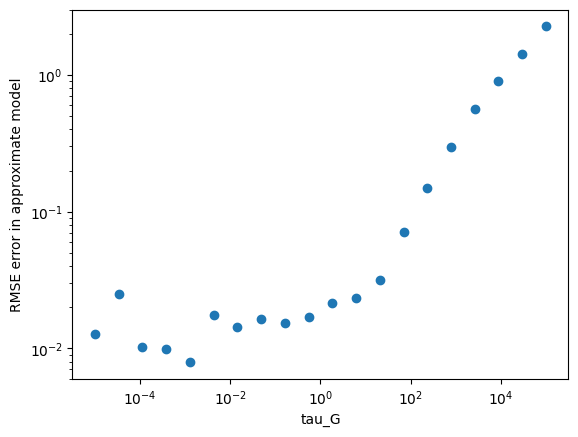

In [15]:


plt.scatter(tau_vals, rmses)
plt.xscale('log')
plt.yscale('log')
plt.ylabel("RMSE error in approximate model")
plt.xlabel("tau_G")